# **MÓDULO 20 - Projeto de Credit Score - Naive Bayes**


No módulo 17 vocês realizaram a primeira etapa do projeto de crédito de vocês.
Então fizeram o tratamendo dos dados, balancearam as classes, transformaram as variáveis categóricas e separam base de treino e teste.
Nessa aula aplicaremos o algoritmo de naive bayes a base de vocês afim de tentarmos trazer previsões do score de crédito.

**IMPORTANTE:** Não se esqueçam de ao enviar o código de vocês para os tutores, enviarem as bases, pois como cada um de vocês realizou as alterações de tratamento indidualmente o tutor precisa ter acesso aos seus dados individuais.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

Durante a aula nossa variável a ser prevista (churn) continha apenas 2 categorias, a base de vocês contém mais. O Naive Bayes pode ser aplicado para problemas de classificação com múltiplas classes da mesma forma que para problemas de classificação binária. O Naive Bayes é um algoritmo de classificação probabilístico que calcula a probabilidade de uma amostra pertencer a cada classe e seleciona a classe com a maior probabilidade como a previsão final.
Em resumo, o Naive Bayes pode ser aplicado da mesma maneira para problemas de classificação com múltiplas classes, e os mesmos princípios se aplicam em termos de treinamento, avaliação e aplicação do modelo.

# 1) Comece carregando as bases de treino (X e y) e teste (X e y).
Verifique se o número de linhas condiz, se as variáveis estão corretas sendo apenas a de score para y e as demais nas bases de X e por último, se Y está balanceada no teste.

In [2]:
df = pd.read_csv("CREDIT_SCORE_BALANCEADO.csv")
display(df.head())

colunas_candidatas = [col for col in df.columns if 'score' in col.lower() or 'credito' in col.lower()]
target_col = colunas_candidatas[0] if colunas_candidatas else df.columns[-1]

y = df[target_col]
X = df.drop(columns=[target_col])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("="*40)
print("1. VERIFICAÇÃO DO NÚMERO DE LINHAS")
print("="*40)
total_original = len(df)
total_dividido = len(X_train) + len(X_test)
print(f"Total original: {total_original}")
print(f"Treino + Teste: {total_dividido}")
print("Status:", "OK" if total_original == total_dividido else "Divergência")

print("\n" + "="*40)
print("2. VERIFICAÇÃO DAS VARIÁVEIS")
print("="*40)
print(f"y: '{target_col}'")
print(f"X: {X.shape[1]} colunas")

print("\n" + "="*40)
print("3. BALANCEAMENTO EM Y (TESTE)")
print("="*40)
print(y_test.value_counts())
print("\nPercentual (%):")
print(y_test.value_counts(normalize=True) * 100)

,Age,Income,Education,Number of Children,Gender_Female,Gender_Male,Marital Status_Married,Marital Status_Single,Home Ownership_Owned,Home Ownership_Rented,Credit Score
0,51,1450000.0,1,0,0,1,1,0,1,0,High
1,40,1300000.0,3,0,0,1,0,1,1,0,High
2,30,1175000.0,4,2,0,1,1,0,1,0,High
3,36,350000.0,3,0,1,0,0,1,0,1,Low
4,25,550000.0,1,0,1,0,0,1,0,1,Average


1. VERIFICAÇÃO DO NÚMERO DE LINHAS
Total original: 270
Treino + Teste: 270
Status: OK

2. VERIFICAÇÃO DAS VARIÁVEIS
y: 'Credit Score'
X: 10 colunas

3. BALANCEAMENTO EM Y (TESTE)
Credit Score
High       20
Low        20
Average    14
Name: count, dtype: int64

Percentual (%):
Credit Score
High       37.037037
Low        37.037037
Average    25.925926
Name: proportion, dtype: float64


# 2) Aplique o algoritmo de Naive Bayes aos dados de treinamento.

In [3]:
df = pd.read_csv("CREDIT_SCORE_BALANCEADO.csv")
display(df.head())

colunas_candidatas = [col for col in df.columns if 'score' in col.lower() or 'credito' in col.lower()]
target_col = colunas_candidatas[0] if colunas_candidatas else df.columns[-1]

y = df[target_col]
X = df.drop(columns=[target_col])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("="*40)
print("1. VERIFICAÇÃO DO NÚMERO DE LINHAS")
print("="*40)
total_original = len(df)
total_dividido = len(X_train) + len(X_test)
print(f"Total original: {total_original}")
print(f"Treino + Teste: {total_dividido}")
print("Status:", "OK" if total_original == total_dividido else "Divergência")

print("\n" + "="*40)
print("2. VERIFICAÇÃO DAS VARIÁVEIS")
print("="*40)
print(f"y: '{target_col}'")
print(f"X: {X.shape[1]} colunas")

print("\n" + "="*40)
print("3. BALANCEAMENTO EM Y (TESTE)")
print("="*40)
print(y_test.value_counts())
print("\nPercentual (%):")
print(y_test.value_counts(normalize=True) * 100)

modelo = GaussianNB()
modelo.fit(X_train, y_train)

print("\n" + "="*40)
print("4. MODELO TREINADO (GaussianNB)")
print("="*40)
display(modelo)
print("\nClasses aprendidas:", modelo.classes_)
print("\nPrioritárias das classes (class_prior_):")
print(modelo.class_prior_)
print("\nMédias aprendidas para cada feature por classe (theta_):")
print(modelo.theta_)

,Age,Income,Education,Number of Children,Gender_Female,Gender_Male,Marital Status_Married,Marital Status_Single,Home Ownership_Owned,Home Ownership_Rented,Credit Score
0,51,1450000.0,1,0,0,1,1,0,1,0,High
1,40,1300000.0,3,0,0,1,0,1,1,0,High
2,30,1175000.0,4,2,0,1,1,0,1,0,High
3,36,350000.0,3,0,1,0,0,1,0,1,Low
4,25,550000.0,1,0,1,0,0,1,0,1,Average


1. VERIFICAÇÃO DO NÚMERO DE LINHAS
Total original: 270
Treino + Teste: 270
Status: OK

2. VERIFICAÇÃO DAS VARIÁVEIS
y: 'Credit Score'
X: 10 colunas

3. BALANCEAMENTO EM Y (TESTE)
Credit Score
High       20
Low        20
Average    14
Name: count, dtype: int64

Percentual (%):
Credit Score
High       37.037037
Low        37.037037
Average    25.925926
Name: proportion, dtype: float64

4. MODELO TREINADO (GaussianNB)


,priors,None
,var_smoothing,1e-09



Classes aprendidas: ['Average' 'High' 'Low']

Prioritárias das classes (class_prior_):
[0.35185185 0.32407407 0.32407407]

Médias aprendidas para cada feature por classe (theta_):
[[3.06842105e+01 5.48014966e+05 9.21052632e-01 6.57894737e-02
  1.71052632e-01 5.65789474e-01 1.31578947e-02 9.47368421e-01
  1.31578947e-02 9.47368421e-01]
 [4.09571429e+01 1.01750000e+06 2.38571429e+00 8.85714286e-01
  4.57142857e-01 5.42857143e-01 7.28571429e-01 2.71428571e-01
  9.42857143e-01 5.71428571e-02]
 [2.96857143e+01 3.15885785e+05 1.10000000e+00 0.00000000e+00
  1.00000000e+00 0.00000000e+00 0.00000000e+00 1.00000000e+00
  0.00000000e+00 1.00000000e+00]]


# 3) Faça a avaliação do modelo com os dados de treinamento.
Traga a acurácia, recall e plote a matriz de confusão. Não se esqueça de avaliar com suas palavras o desempenho do modelo, interpretando as métricas.

Dica: Para calcularmos o recall em classificação multi classe precisamos usar o atributo macro:
recall = recall_score(y_train, y_pred_train, average='macro')

In [4]:
df = pd.read_csv("CREDIT_SCORE_BALANCEADO.csv")
display(df.head())

colunas_candidatas = [col for col in df.columns if 'score' in col.lower() or 'credito' in col.lower()]
target_col = colunas_candidatas[0] if colunas_candidatas else df.columns[-1]

y = df[target_col]
X = df.drop(columns=[target_col])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("="*40)
print("1. VERIFICAÇÃO DO NÚMERO DE LINHAS")
print("="*40)
total_original = len(df)
total_dividido = len(X_train) + len(X_test)
print(f"Total original: {total_original}")
print(f"Treino + Teste: {total_dividido}")
print("Status:", "OK" if total_original == total_dividido else "Divergência")

print("\n" + "="*40)
print("2. VERIFICAÇÃO DAS VARIÁVEIS")
print("="*40)
print(f"y: '{target_col}'")
print(f"X: {X.shape[1]} colunas")

print("\n" + "="*40)
print("3. BALANCEAMENTO EM Y (TESTE)")
print("="*40)
print(y_test.value_counts())
print("\nPercentual (%):")
print(y_test.value_counts(normalize=True) * 100)

modelo = GaussianNB()
modelo.fit(X_train, y_train)

print("\n" + "="*40)
print("4. MODELO TREINADO (GaussianNB)")
print("="*40)
display(modelo)
print("\nClasses aprendidas:", modelo.classes_)

y_pred_train = modelo.predict(X_train)

print("\n" + "="*40)
print("5. AVALIAÇÃO NOS DADOS DE TREINO")
print("="*40)
acuracia_train = accuracy_score(y_train, y_pred_train)
recall_train = recall_score(y_train, y_pred_train, average='macro')
matriz_conf_train = confusion_matrix(y_train, y_pred_train)

print(f"Acurácia (Treino): {acuracia_train:.4f}")
print(f"Recall Macro (Treino): {recall_train:.4f}")

classes = modelo.classes_
fig = px.imshow(
    matriz_conf_train,
    x=classes,
    y=classes,
    text_auto=True,
    color_continuous_scale="Blues",
    labels=dict(x="Valor Previsto", y="Valor Real", color="Contagem")
)
fig.update_layout(
    title="Matriz de Confusão Interativa (Treino)",
    xaxis_title="Previsto",
    yaxis_title="Real"
)
fig.show()

,Age,Income,Education,Number of Children,Gender_Female,Gender_Male,Marital Status_Married,Marital Status_Single,Home Ownership_Owned,Home Ownership_Rented,Credit Score
0,51,1450000.0,1,0,0,1,1,0,1,0,High
1,40,1300000.0,3,0,0,1,0,1,1,0,High
2,30,1175000.0,4,2,0,1,1,0,1,0,High
3,36,350000.0,3,0,1,0,0,1,0,1,Low
4,25,550000.0,1,0,1,0,0,1,0,1,Average


1. VERIFICAÇÃO DO NÚMERO DE LINHAS
Total original: 270
Treino + Teste: 270
Status: OK

2. VERIFICAÇÃO DAS VARIÁVEIS
y: 'Credit Score'
X: 10 colunas

3. BALANCEAMENTO EM Y (TESTE)
Credit Score
High       20
Low        20
Average    14
Name: count, dtype: int64

Percentual (%):
Credit Score
High       37.037037
Low        37.037037
Average    25.925926
Name: proportion, dtype: float64

4. MODELO TREINADO (GaussianNB)


,priors,None
,var_smoothing,1e-09



Classes aprendidas: ['Average' 'High' 'Low']

5. AVALIAÇÃO NOS DADOS DE TREINO
Acurácia (Treino): 0.9630
Recall Macro (Treino): 0.9623


# 4) Aplique o modelo aos dados de teste e realize a avaliação dos resultados, da mesma forma que fez acima. Não se esqueça de avaliar com as suas palavras e comparar o desempenho da base treino com a teste.

,Age,Income,Education,Number of Children,Gender_Female,Gender_Male,Marital Status_Married,Marital Status_Single,Home Ownership_Owned,Home Ownership_Rented,Credit Score
0,51,1450000.0,1,0,0,1,1,0,1,0,High
1,40,1300000.0,3,0,0,1,0,1,1,0,High
2,30,1175000.0,4,2,0,1,1,0,1,0,High
3,36,350000.0,3,0,1,0,0,1,0,1,Low
4,25,550000.0,1,0,1,0,0,1,0,1,Average


1. VERIFICAÇÃO DO NÚMERO DE LINHAS
Total original: 270
Treino + Teste: 270
Status: OK

2. VERIFICAÇÃO DAS VARIÁVEIS
y: 'Credit Score'
X: 10 colunas

3. BALANCEAMENTO EM Y (TESTE)
Credit Score
High       20
Low        20
Average    14
Name: count, dtype: int64

Percentual (%):
Credit Score
High       37.037037
Low        37.037037
Average    25.925926
Name: proportion, dtype: float64

4. MODELO TREINADO (GaussianNB)


,priors,None
,var_smoothing,1e-09



Classes aprendidas: ['Average' 'High' 'Low']

5. AVALIAÇÃO NOS DADOS DE TREINO
Acurácia (Treino): 0.9630
Recall Macro (Treino): 0.9623


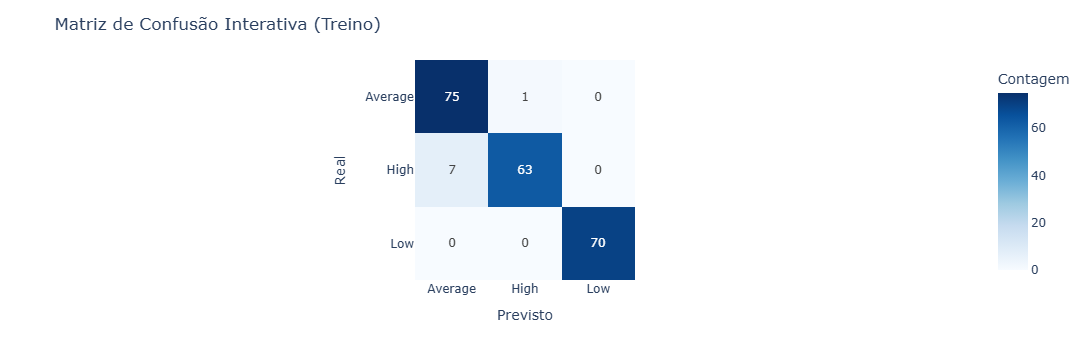


6. AVALIAÇÃO NOS DADOS DE TESTE
Acurácia (Teste): 0.9444
Recall Macro (Teste): 0.9500


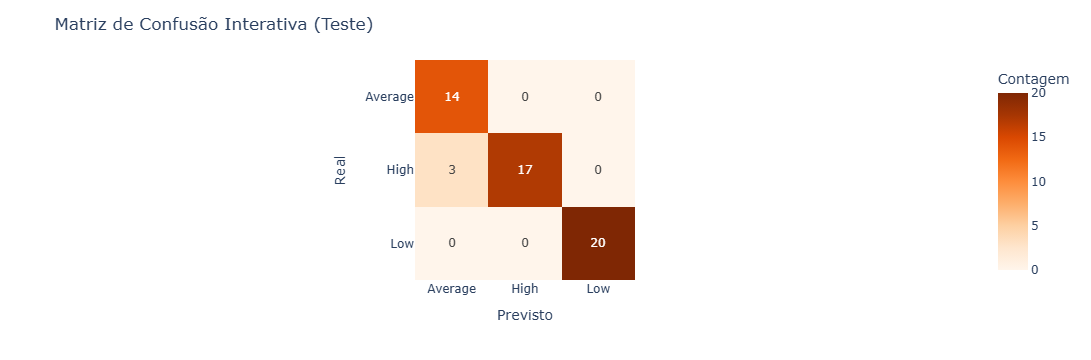


7. COMPARAÇÃO ENTRE TREINO E TESTE
Diferença de Acurácia (Treino - Teste): 0.0185
Diferença de Recall (Treino - Teste): 0.0123


In [5]:
df = pd.read_csv("CREDIT_SCORE_BALANCEADO.csv")
display(df.head())

colunas_candidatas = [col for col in df.columns if 'score' in col.lower() or 'credito' in col.lower()]
target_col = colunas_candidatas[0] if colunas_candidatas else df.columns[-1]

y = df[target_col]
X = df.drop(columns=[target_col])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("="*40)
print("1. VERIFICAÇÃO DO NÚMERO DE LINHAS")
print("="*40)
total_original = len(df)
total_dividido = len(X_train) + len(X_test)
print(f"Total original: {total_original}")
print(f"Treino + Teste: {total_dividido}")
print("Status:", "OK" if total_original == total_dividido else "Divergência")

print("\n" + "="*40)
print("2. VERIFICAÇÃO DAS VARIÁVEIS")
print("="*40)
print(f"y: '{target_col}'")
print(f"X: {X.shape[1]} colunas")

print("\n" + "="*40)
print("3. BALANCEAMENTO EM Y (TESTE)")
print("="*40)
print(y_test.value_counts())
print("\nPercentual (%):")
print(y_test.value_counts(normalize=True) * 100)

modelo = GaussianNB()
modelo.fit(X_train, y_train)

print("\n" + "="*40)
print("4. MODELO TREINADO (GaussianNB)")
print("="*40)
display(modelo)
print("\nClasses aprendidas:", modelo.classes_)

y_pred_train = modelo.predict(X_train)

print("\n" + "="*40)
print("5. AVALIAÇÃO NOS DADOS DE TREINO")
print("="*40)
acuracia_train = accuracy_score(y_train, y_pred_train)
recall_train = recall_score(y_train, y_pred_train, average='macro')
matriz_conf_train = confusion_matrix(y_train, y_pred_train)

print(f"Acurácia (Treino): {acuracia_train:.4f}")
print(f"Recall Macro (Treino): {recall_train:.4f}")

classes = modelo.classes_
fig_train = px.imshow(
    matriz_conf_train,
    x=classes,
    y=classes,
    text_auto=True,
    color_continuous_scale="Blues",
    labels=dict(x="Valor Previsto", y="Valor Real", color="Contagem")
)
fig_train.update_layout(
    title="Matriz de Confusão Interativa (Treino)",
    xaxis_title="Previsto",
    yaxis_title="Real"
)
fig_train.show()

y_pred_test = modelo.predict(X_test)

print("\n" + "="*40)
print("6. AVALIAÇÃO NOS DADOS DE TESTE")
print("="*40)
acuracia_test = accuracy_score(y_test, y_pred_test)
recall_test = recall_score(y_test, y_pred_test, average='macro')
matriz_conf_test = confusion_matrix(y_test, y_pred_test)

print(f"Acurácia (Teste): {acuracia_test:.4f}")
print(f"Recall Macro (Teste): {recall_test:.4f}")

fig_test = px.imshow(
    matriz_conf_test,
    x=classes,
    y=classes,
    text_auto=True,
    color_continuous_scale="Oranges",
    labels=dict(x="Valor Previsto", y="Valor Real", color="Contagem")
)
fig_test.update_layout(
    title="Matriz de Confusão Interativa (Teste)",
    xaxis_title="Previsto",
    yaxis_title="Real"
)
fig_test.show()

print("\n" + "="*40)
print("7. COMPARAÇÃO ENTRE TREINO E TESTE")
print("="*40)
print(f"Diferença de Acurácia (Treino - Teste): {(acuracia_train - acuracia_test):.4f}")
print(f"Diferença de Recall (Treino - Teste): {(recall_train - recall_test):.4f}")

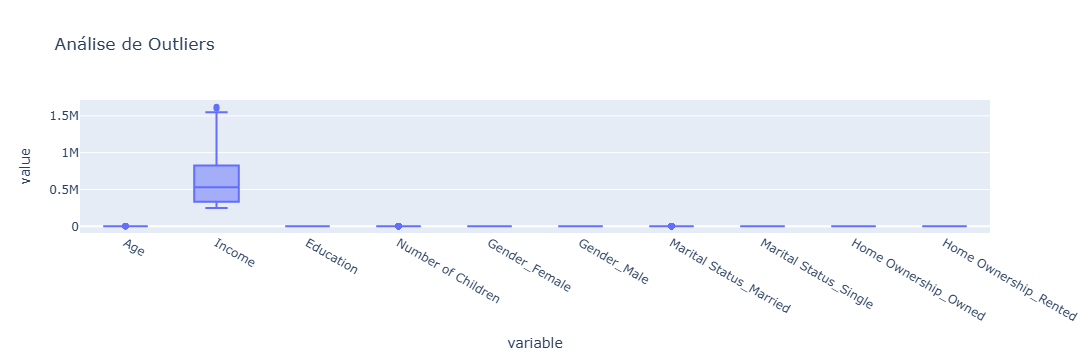

In [6]:
df = pd.read_csv("CREDIT_SCORE_BALANCEADO.csv")

colunas_numericas = df.select_dtypes(include=['float64', 'int64']).columns

fig = px.box(df, y=colunas_numericas, title="Análise de Outliers")
fig.show()

# 5) Descreva com suas palavras o projeto desenvolvido nessa atividade e qual o nosso objetivo principal ao aplicarmos o algoritmo de naive bayes a base de crédito.
Utilize pelo menos 4 linhas.

Dica: Caso você ainda esteja tendo dificuldade em visualizar a aplicação dos projetos e objetivo, consulte seus tutores!

In [ ]:
# O objetivo do projeto é classificar o perfil de score de crédito de clientes com base em seus dados financeiros, automatizando a análise de risco
# por meio de um pipeline validado de Machine Learning. O algoritmo Naive Bayes atua como o classificador estatístico central, utilizando probabilidades
# condicionais para prever a classe de forma rápida e eficiente.